# Nonlinear ODE Problem Set Solutions

**References:** `Notes/Problem Set II.pdf` (Q2, Q4, Q5), `Notes/lec10.pdf`, `Notes/lec11.pdf`

Grouped by question type:
1. **Type 1:** 1D Nonlinear Flows & Fixed-Point Analysis (`Problem Set II.pdf` Q2 i, ii, iii)
2. **Type 2:** 2D Nonlinear Competition System (`Problem Set II.pdf` Q4)
3. **Type 3:** Bead on a Rotating Hoop & Overdamped Reduction (`Problem Set II.pdf` Q5)

---
## Type 1: 1D Nonlinear Flows (`Problem Set II.pdf` Q2)
### Q2 (i): $\dot{x} = rx + x^3 - x^5$
- Fixed points: $x^* = 0$ always, and $x^2 = \frac{1 \pm \sqrt{1 + 4r}}{2}$ when real and positive.
- At $r = 0.4$: $x^* = 0$ is **unstable** ($f'(0) = 0.4 > 0$), and $x^* \approx \pm 1.14$ are **stable**.
- So Simple Euler starting at $x(0) = 0.5$ approaches $+1.14$, and $x(0) = -0.5$ approaches $-1.14$.

Positive stable fixed point x* = 1.1429
Final x(t) from +0.5: 1.1429
Final x(t) from -0.5: -1.1429


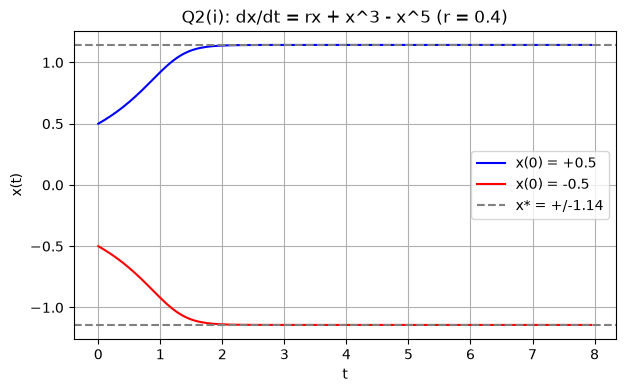

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Q2 (i): Numerical integration with Simple Euler at r = 0.4
r = 0.4
dt = 0.05
t = np.arange(0, 8, dt)
n = len(t)

x_pos = np.zeros(n); x_pos[0] = 0.5
x_neg = np.zeros(n); x_neg[0] = -0.5

for i in range(n - 1):
    x_pos[i + 1] = x_pos[i] + dt * (r * x_pos[i] + x_pos[i]**3 - x_pos[i]**5)
    x_neg[i + 1] = x_neg[i] + dt * (r * x_neg[i] + x_neg[i]**3 - x_neg[i]**5)

x_star = np.sqrt((1 + np.sqrt(1 + 4*r)) / 2)
print('Positive stable fixed point x* =', round(x_star, 4))
print('Final x(t) from +0.5:', round(x_pos[-1], 4))
print('Final x(t) from -0.5:', round(x_neg[-1], 4))

plt.figure(figsize=(7, 4))
plt.plot(t, x_pos, 'b-', label='x(0) = +0.5')
plt.plot(t, x_neg, 'r-', label='x(0) = -0.5')
plt.axhline( x_star, color='gray', linestyle='--', label=f'x* = +/-{x_star:.2f}')
plt.axhline(-x_star, color='gray', linestyle='--')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Q2(i): dx/dt = rx + x^3 - x^5 (r = 0.4)')
plt.legend()
plt.grid(True)
plt.show()

### Q2 (ii): Spruce Budworm Equation $\dot{x} = \frac{2x}{5}\left(1 - \frac{x}{20}\right) - \frac{x^2}{1 + x^2}$
Plot $f(x)$ vs $x$ to read off all fixed points (roots) and their stability (downward crossing = stable, upward crossing = unstable).

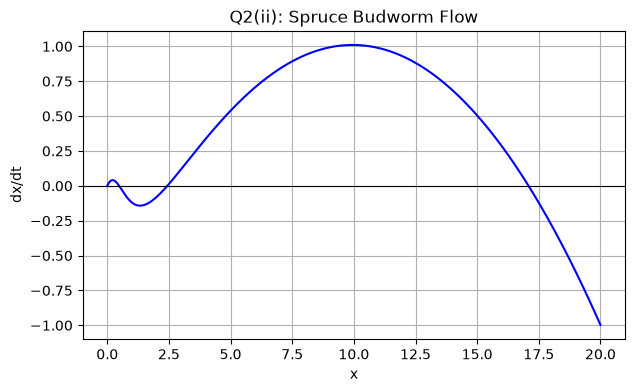

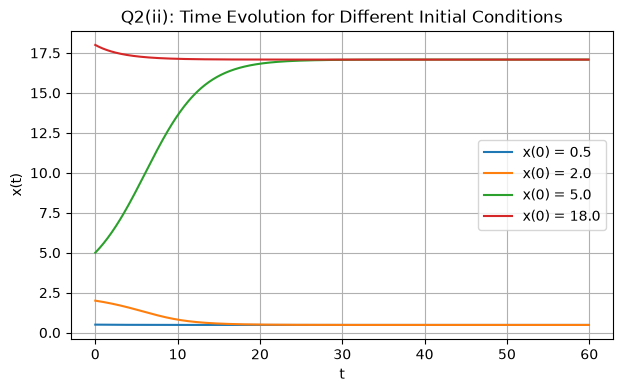

In [2]:
# Q2 (ii): Plot f(x) to see fixed points and stability
x_grid = np.linspace(0, 20, 400)
f_budworm = 0.4 * x_grid * (1 - x_grid / 20) - (x_grid**2) / (1 + x_grid**2)

plt.figure(figsize=(7, 4))
plt.plot(x_grid, f_budworm, 'b-')
plt.axhline(0, color='k', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.title('Q2(ii): Spruce Budworm Flow')
plt.grid(True)
plt.show()

# Check long-term trajectories from two initial values
dt = 0.1
t = np.arange(0, 60, dt)
plt.figure(figsize=(7, 4))
for x0 in [0.5, 2.0, 5.0, 18.0]:
    x = np.zeros(len(t))
    x[0] = x0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + dt * (0.4 * x[i] * (1 - x[i] / 20) - (x[i]**2) / (1 + x[i]**2))
    plt.plot(t, x, label=f'x(0) = {x0}')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Q2(ii): Time Evolution for Different Initial Conditions')
plt.legend()
plt.grid(True)
plt.show()

### Q2 (iii): $\dot{x} = rx - \ln(1 + x)$ (defined for $x > -1$)
- $x^* = 0$ is always a fixed point, with $f'(0) = r - 1$.
- **$r > 1$:** $x^* = 0$ is unstable ($f'(0) > 0$), plus another **stable** fixed point $x^* > 0$.
- **$r < 1$:** $x^* = 0$ is **stable** ($f'(0) < 0$), plus another unstable fixed point in $(-1, 0)$ when $r > 0$.

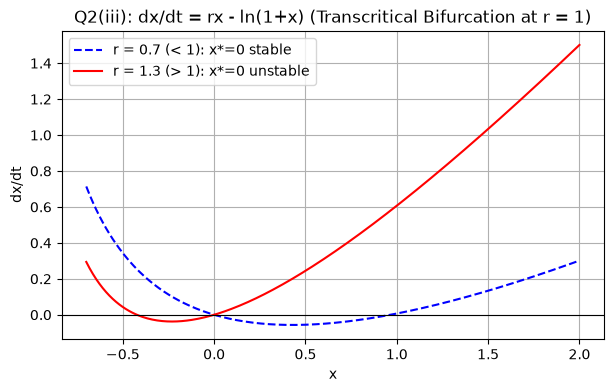

In [3]:
# Q2 (iii): Plot dx/dt = rx - ln(1 + x) for r < 1 and r > 1
x_grid = np.linspace(-0.7, 2.0, 300)

plt.figure(figsize=(7, 4))
plt.plot(x_grid, 0.7 * x_grid - np.log(1 + x_grid), 'b--', label='r = 0.7 (< 1): x*=0 stable')
plt.plot(x_grid, 1.3 * x_grid - np.log(1 + x_grid), 'r-',  label='r = 1.3 (> 1): x*=0 unstable')
plt.axhline(0, color='k', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.title('Q2(iii): dx/dt = rx - ln(1+x) (Transcritical Bifurcation at r = 1)')
plt.legend()
plt.grid(True)
plt.show()

---
## Type 2: 2D Nonlinear Competition System (`Problem Set II.pdf` Q4)
System: $\dot{x} = x(3 - x - 2y)$, $\dot{y} = y(2 - y - x)$.

- **Fixed points:** $(0,0), (3,0), (0,2), (1,1)$.
- **Jacobian:** $J(x,y) = \begin{pmatrix} 3 - 2x - 2y & -2x \\ -y & 2 - 2y - x \end{pmatrix}$.

Fixed point (0, 0): eigenvalues = [3.+0.j 2.+0.j]
Fixed point (3, 0): eigenvalues = [-3.+0.j -1.+0.j]
Fixed point (0, 2): eigenvalues = [-2.+0.j -1.+0.j]
Fixed point (1, 1): eigenvalues = [ 0.414+0.j -2.414+0.j]


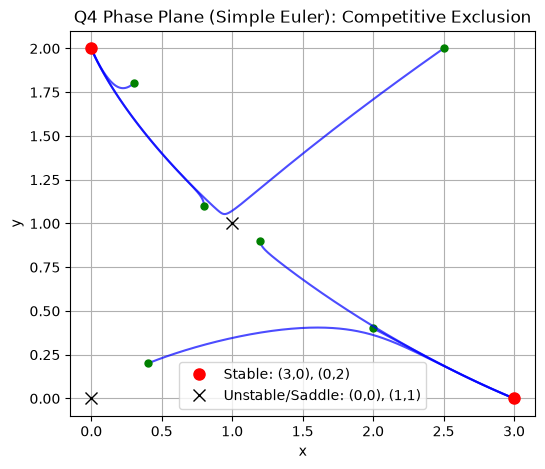

In [4]:
# Q4: Check Jacobian eigenvalues at all 4 fixed points
fixed_points = [(0, 0), (3, 0), (0, 2), (1, 1)]

for fp in fixed_points:
    x_s, y_s = fp
    J = np.array([[3 - 2*x_s - 2*y_s, -2*x_s],
                  [-y_s,               2 - 2*y_s - x_s]])
    vals = np.linalg.eigvals(J)
    print(f'Fixed point {fp}: eigenvalues = {np.round(vals, 3)}')

# Numerical phase plane with Simple Euler from several starting points
dt = 0.02
t = np.arange(0, 12, dt)
n = len(t)

plt.figure(figsize=(6, 5))
starts = [(0.4, 0.2), (2.0, 0.4), (0.3, 1.8), (2.5, 2.0), (1.2, 0.9), (0.8, 1.1)]
for x0, y0 in starts:
    x = np.zeros(n); y = np.zeros(n)
    x[0], y[0] = x0, y0
    for i in range(n - 1):
        dx = x[i] * (3 - x[i] - 2*y[i])
        dy = y[i] * (2 - y[i] - x[i])
        x[i + 1] = x[i] + dt * dx
        y[i + 1] = y[i] + dt * dy
    plt.plot(x, y, 'b-', alpha=0.7)
    plt.plot(x[0], y[0], 'go', markersize=5)

plt.plot([3, 0], [0, 2], 'ro', markersize=8, label='Stable: (3,0), (0,2)')
plt.plot([0, 1], [0, 1], 'kx', markersize=8, label='Unstable/Saddle: (0,0), (1,1)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Q4 Phase Plane (Simple Euler): Competitive Exclusion')
plt.legend()
plt.grid(True)
plt.show()

---
## Type 3: Bead on a Rotating Hoop (`Problem Set II.pdf` Q5)
Full equation: $mr\ddot{\varphi} = -br\dot{\varphi} - mg\sin\varphi + mr\omega^2\sin\varphi\cos\varphi$.

- **Overdamped timescale:** $\tau = \frac{br}{mg}$, valid when $\frac{m^2 g}{b^2 r} \ll 1$ (dropping $mr\ddot{\varphi}$ gives $br\dot{\varphi} = -mg\sin\varphi + mr\omega^2\sin\varphi\cos\varphi$).
- **Parameters:** $m=1,\; b=20,\; \omega=5,\; r=1,\; g=9.8,\; \varphi(0)=0.5,\; \dot{\varphi}(0)=0$.

Overdamped check (m^2*g / (b^2*r)) = 0.0245 << 1
Analytical stable angle cos(phi) = g/(r*w^2) -> phi* = 1.1680 rad


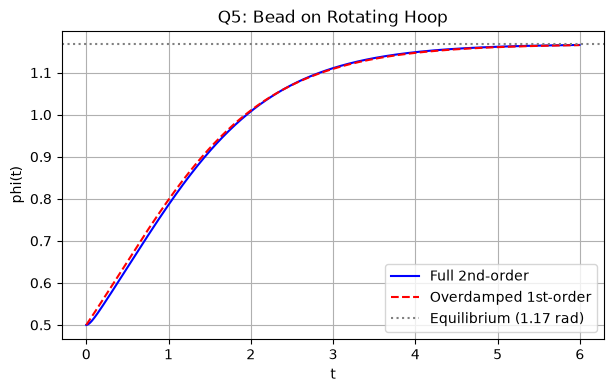

In [5]:
# Q5: Compare Full 2nd-Order Hoop Equation vs Overdamped 1st-Order Approximation
m, b, omega, r, g = 1.0, 20.0, 5.0, 1.0, 9.8

ratio = (m**2 * g) / (b**2 * r)
print(f'Overdamped check (m^2*g / (b^2*r)) = {ratio:.4f} << 1')

dt = 0.005
t = np.arange(0, 6.0, dt)
n = len(t)

# Full system: phi and v = d(phi)/dt
phi_full = np.zeros(n); v_full = np.zeros(n)
phi_full[0] = 0.5; v_full[0] = 0.0

# Overdamped 1st-order system
phi_over = np.zeros(n)
phi_over[0] = 0.5

for i in range(n - 1):
    # Full 2nd-order Euler
    accel = (-b * r * v_full[i] - m * g * np.sin(phi_full[i])
             + m * r * (omega**2) * np.sin(phi_full[i]) * np.cos(phi_full[i])) / (m * r)
    v_full[i + 1] = v_full[i] + dt * accel
    phi_full[i + 1] = phi_full[i] + dt * v_full[i + 1]

    # Overdamped 1st-order Euler
    dphi = (-m * g * np.sin(phi_over[i])
            + m * r * (omega**2) * np.sin(phi_over[i]) * np.cos(phi_over[i])) / (b * r)
    phi_over[i + 1] = phi_over[i] + dt * dphi

phi_eq = np.arccos(g / (r * omega**2))
print(f'Analytical stable angle cos(phi) = g/(r*w^2) -> phi* = {phi_eq:.4f} rad')

plt.figure(figsize=(7, 4))
plt.plot(t, phi_full, 'b-', label='Full 2nd-order')
plt.plot(t, phi_over, 'r--', label='Overdamped 1st-order')
plt.axhline(phi_eq, color='gray', linestyle=':', label=f'Equilibrium ({phi_eq:.2f} rad)')
plt.xlabel('t')
plt.ylabel('phi(t)')
plt.title('Q5: Bead on Rotating Hoop')
plt.legend()
plt.grid(True)
plt.show()